# Example 1

In [184]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
from scipy.integrate import solve_ivp, trapezoid

rng = np.random.default_rng(seed=42)

### Parameters and initial conditions

In [185]:
a1 = 1.0
a2 = 2.0
ar = 1.5
br = 1.0  

beta = np.array([1.0, 1.0], dtype=float)
alpha = 1.0

# SciPy expects an initial-state vector, even for a one-state model.
x0 = beta.copy()
x_hat0 = np.array([alpha], dtype=float)

def u(t):
    """Scalar input; initially zero to study initial-condition responses."""
    return 0.0

### Time grid and sample counts


In [186]:
T = 10.0  # Final time
N_t = 1001
N_beta1 = 201
N_beta2 = 201
N_beta = N_beta1 * N_beta2

# deltat = T / (N_t - 1)
tp = np.linspace(0, T, N_t) 

In [187]:
beta1 = rng.random(200)
beta2 = rng.random(200)

beta1 = beta1.reshape(200, 1)
beta2 = beta2.reshape(200, 1)

B = np.hstack((beta1, beta2))

### Deatailed Model 

In [188]:
y_exact = beta1 * np.exp(-a1 * tp) + beta2 * np.exp(-a2 * tp)

### Ruduced models

In [189]:
psi_k = np.exp(-ar * tp)
y_hat = alpha*psi_k
y_r = y_hat

### Closed-form cross-level quantities

In [190]:
# finite-horizon matrices
QT = np.array([[(1-np.exp(-2*a1*T))/(2*a1), (1-np.exp(-(a1+a2)*T))/(a1+a2)],
              [(1-np.exp(-(a1+a2)*T))/(a1+a2), (1-np.exp(-2*a2*T))/(2*a2)]])

r = (1-np.exp(-2*ar*T))/(2*ar)
QT_hat = r

q = np.array([[(1-np.exp(-(a1+ar)*T))/(a1+ar)],
              [(1-np.exp(-(ar+a2)*T))/(ar+a2)]])

ET = QT - np.multiply(q, q.transpose())/r

## Verify the Optiaml Reduced Parameters Map

In [191]:
alpha_star =np.zeros((200,1))
for idx, val in enumerate(B):
    val = val.reshape((2, 1))
    alpha_star[idx] = q.T @ val / r
alpha_star = np.array((alpha_star))

In [192]:
alpha_star = q.T*B / r

### Generate True Values

In [193]:
# choose the 100th as true value
beta_true = [beta1[99, 0], beta2[99, 0]]

y_true = beta_true[0] * np.exp(-a1 * tp) + beta_true[1] * np.exp(-a2 * tp)

In [194]:
mean = 0.0          # Mean of the Gaussian distribution
std_dev = 0.1       # Standard deviation (controls noise amplitude)

noise = np.random.normal(mean, std_dev, N_t)

y_bar = y_true + noise

### Likelihood and Prior Preparation

In [195]:
detailed_param_names = ["beta1", "beta2"]

detailed_lower_bounds = np.array([0., 0.])
detailed_upper_bounds = np.array([1., 1.])

detailed_prior = {
    "beta1": ["normal", 0.5, 0.5],
    "beta2": ["normal", 0.5, 0.5],
}

In [196]:
data = {
    "t": tp,
    "y_obs": y_bar
}

In [197]:
def detailed_log_likelihood(params_dict, data):
    # data is the previously generated y_bar.
    beta1 = params_dict["beta1"]
    beta2 = params_dict["beta2"]
    tp = data["t"]
    y_obs = data["y_obs"]
    y = beta1 * np.exp(-a1 * tp) + beta2 * np.exp(-a2 * tp)

    squared_error_integral = trapezoid((y - y_obs)**2, x=tp)
    # Time-integrated Gaussian misfit, up to an additive constant.
    return -np.log(squared_error_integral/2)

### Quick-run setting for MCMC

In [198]:
from implementation_methods import (
    py_inference,
    build_behavioral_gp_from_reduced_posterior,
)


In [199]:
# MCMC settings
NWALKERS = 16
NSTEPS = 1000
BURN = 200
RANDOM_SEED = 42

#### 1. Baseline detailed-model inference

In [200]:
detailed_result = py_inference(
    likelihood=detailed_log_likelihood,
    data=data,
    params_to_estimate=detailed_param_names,
    prior=detailed_prior,
    nwalkers=NWALKERS,
    nsteps=NSTEPS,
    discard=BURN,
    random_seed=RANDOM_SEED,
)

#### 2. Reduced-model inference

In [201]:
reduced_param_names = ["alpha"]

reduced_prior = {
   "alpha": ["normal", 1.0, 0.5],
}

In [202]:
data = {
    "t": tp,
    "y_hat": y_r,
}

In [203]:
def reduced_log_likelihood(params_dict, data):
    # Returns one scalar log likelihood.
    alpha = params_dict["alpha"]
    tp = data['t']
    y_hat = data["y_hat"]
    y = alpha*np.exp(-ar*tp)
    
    squared_error_integral = trapezoid((y - y_hat)**2, x=tp)
    return -np.log(squared_error_integral/2)
    


In [204]:
reduced_result = py_inference(
    likelihood=reduced_log_likelihood,
    data=data,
    params_to_estimate=reduced_param_names,
    prior=reduced_prior,
    nwalkers=NWALKERS,
    nsteps=NSTEPS,
    discard=BURN,
    random_seed=RANDOM_SEED,
)

/var/folders/bw/n963nht16z7bt_qblpq0h78h0000gn/T/ipykernel_32585/1682195686.py:9: RuntimeWarning: divide by zero encountered in log
  return -np.log(squared_error_integral/2)


#### 3. Learn the behavioral-support level set with GP-MPM

In [205]:
def detailed_trajectory_fn(params_dict):
    # Returns the detailed trajectory in the same representation
    # used by the reduced model and observed data.
    beta1 = params_dict["beta1"]
    beta2 = params_dict["beta2"]
    y = beta1 * np.exp(-a1 * tp) + beta2 * np.exp(-a2 * tp)
    return y
    
def reduced_trajectory_fn(params_dict):
    # Returns one scalar log likelihood.
    alpha = params_dict["alpha"]
    y = alpha*np.exp(-ar*tp)
    return y
        

In [206]:
y_obs = y_bar

epsilon = 0.2
ita = 0.15
zeta = 0.01
gamma = 0.8

posterior_level_set_boundary = gamma
data_discrepancy_threshold = ita
gp_screening_level = zeta

RANDOM_SEED = 42

In [207]:
gp_result = build_behavioral_gp_from_reduced_posterior(
    reduced_result.flat_samples,

    reduced_param_names=reduced_param_names,
    reduced_trajectory_fn=reduced_trajectory_fn,

    detailed_param_names=detailed_param_names,
    detailed_lower_bounds=detailed_lower_bounds,
    detailed_upper_bounds=detailed_upper_bounds,
    detailed_trajectory_fn=detailed_trajectory_fn,

    observed_trajectory=y_obs,

    epsilon=epsilon,
    posterior_level_set_boundary=posterior_level_set_boundary,
    data_discrepancy_threshold=data_discrepancy_threshold,
    gp_screening_level=gp_screening_level,

    detailed_log_scale=False,

    random_seed=RANDOM_SEED,
)

/opt/miniconda3/envs/simphsi/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/opt/miniconda3/envs/simphsi/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/opt/miniconda3/envs/simphsi/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/opt/miniconda3/envs/simphsi/lib/python3.12/site-

#### 4. Behaviorally guided detailed-model inference

In [208]:
detailed_data = {"t": tp, "y_obs": y_bar}

detailed_gp_result = py_inference(
    likelihood=detailed_log_likelihood,
    data=detailed_data,
    params_to_estimate=detailed_param_names,
    prior=detailed_prior,
    custom_joint_prior=gp_result.custom_joint_prior,
    nwalkers=NWALKERS,
    nsteps=NSTEPS,
    discard=BURN,
    random_seed=RANDOM_SEED,
)

### Results Visualization

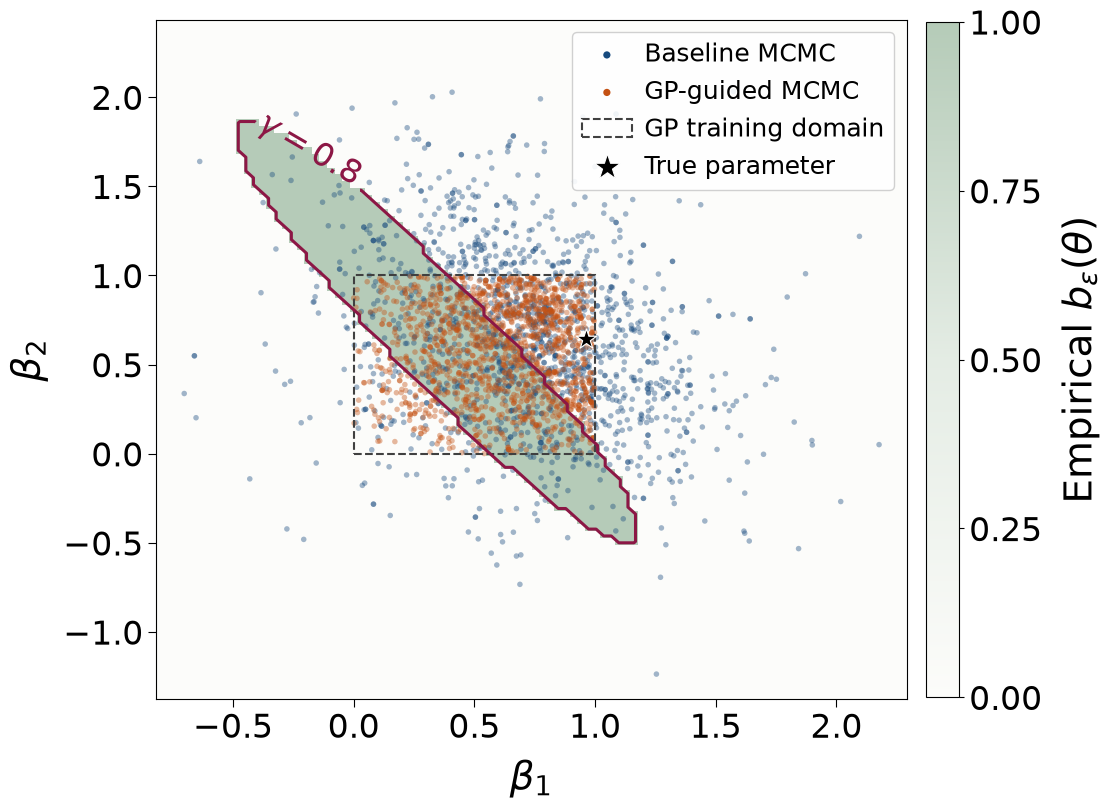

Figure 1. Joint parameter samples over empirical behavioral support — L2; epsilon=0.2, gamma=0.8.


In [209]:
SUPPORT_METRIC = "L2"
SUPPORT_MAP_POINTS = 100
JOINT_MAX_POINTS = 1500
JOINT_POINT_ALPHA = 0.40
TICK_FONT_SIZE = 24
AXIS_FONT_SIZE = 28
LEGEND_FONT_SIZE = 18
GAMMA_FONT_SIZE = 24
GAMMA_LABEL_POSITION = None  # Optional (beta1, beta2) position on the contour.
PAPER_FIGSIZE = (11, 8)
from matplotlib.colors import LinearSegmentedColormap
SUPPORT_CMAP = LinearSegmentedColormap.from_list(
    "soft_support", ["#fcfcfa", "#e4ece4", "#b5cbb8"]
)
from matplotlib.patches import Rectangle

normal_model = gp_result.validity_model
normal_epsilon = float(gp_result.epsilon)
normal_gamma = float(gp_result.posterior_level_set_boundary)
normal_base = np.asarray(detailed_result.flat_samples)[:,
    [list(detailed_result.param_names).index(n) for n in ("beta1", "beta2")]]
normal_guided = np.asarray(detailed_gp_result.flat_samples)[:,
    [list(detailed_gp_result.param_names).index(n) for n in ("beta1", "beta2")]]
normal_alpha = np.sort(np.asarray(gp_result.reduced_posterior_samples)[:, list(reduced_param_names).index("alpha")])
normal_gp_order = [list(normal_model.param_names).index(n) for n in ("beta1", "beta2")]
normal_lo = normal_model.lower_bounds[normal_gp_order]
normal_hi = normal_model.upper_bounds[normal_gp_order]

normal_pool = np.vstack([normal_base, normal_guided, normal_lo, normal_hi, np.asarray(beta_true).reshape(1,2)])
normal_plot_lo = normal_pool.min(axis=0)
normal_plot_hi = normal_pool.max(axis=0)
normal_padding = 0.04 * np.maximum(normal_plot_hi-normal_plot_lo, 1e-6)
normal_plot_lo -= normal_padding
normal_plot_hi += normal_padding
normal_x = np.linspace(normal_plot_lo[0], normal_plot_hi[0], SUPPORT_MAP_POINTS)
normal_y = np.linspace(normal_plot_lo[1], normal_plot_hi[1], SUPPORT_MAP_POINTS)
normal_X, normal_Y = np.meshgrid(normal_x, normal_y)
normal_theta = np.column_stack([normal_X.ravel(), normal_Y.ravel()])

if SUPPORT_METRIC == "L2":
    def normal_int(rate):
        return -np.expm1(-rate*T)/rate
    normal_Q = np.array([[normal_int(2*a1), normal_int(a1+a2)],
                          [normal_int(a1+a2), normal_int(2*a2)]])
    normal_q = np.array([normal_int(a1+ar), normal_int(a2+ar)])
    normal_r = normal_int(2*ar)
    normal_metric_label = r"continuous $L^2$ (screenshot)"
elif SUPPORT_METRIC == "RMSE":
    normal_phi = np.column_stack([np.exp(-a1*tp), np.exp(-a2*tp)])
    normal_psi = np.exp(-ar*tp)
    normal_Q = normal_phi.T@normal_phi/len(tp)
    normal_q = normal_phi.T@normal_psi/len(tp)
    normal_r = normal_psi@normal_psi/len(tp)
    normal_metric_label = "sampled RMSE (GP training metric)"
else:
    raise ValueError('SUPPORT_METRIC must be "L2" or "RMSE".')
normal_E = normal_Q - np.outer(normal_q, normal_q)/normal_r
normal_center = normal_theta@normal_q/normal_r
normal_budget = normal_epsilon**2 - np.einsum("ni,ij,nj->n", normal_theta, normal_E, normal_theta)
normal_radius = np.sqrt(np.maximum(normal_budget, 0)/normal_r)

normal_left = np.searchsorted(normal_alpha, normal_center-normal_radius,
                              side="right" if SUPPORT_METRIC == "L2" else "left")
normal_right = np.searchsorted(normal_alpha, normal_center+normal_radius,
                               side="left" if SUPPORT_METRIC == "L2" else "right")
normal_b = np.maximum(normal_right-normal_left, 0)/len(normal_alpha)
normal_b[normal_budget < 0] = 0
normal_b_map = normal_b.reshape(normal_X.shape)

normal_plot_rng = np.random.default_rng(42)
normal_selected = [(samples[normal_plot_rng.choice(len(samples), min(JOINT_MAX_POINTS,len(samples)),replace=False)], color, label)
    for samples,color,label in [(normal_base,"#174a7e","Baseline MCMC"),(normal_guided,"#c45113","GP-guided MCMC")]]

def draw_normal_support(ax, fig):
    mesh = ax.pcolormesh(normal_X, normal_Y, normal_b_map, cmap=SUPPORT_CMAP,
                         vmin=0, vmax=1, shading="auto", rasterized=True, zorder=0)
    colorbar = fig.colorbar(mesh, ax=ax, pad=0.025, fraction=0.045)
    colorbar.set_label(r"Empirical $b_\epsilon(\theta)$", fontsize=AXIS_FONT_SIZE, labelpad=14)
    colorbar.ax.tick_params(labelsize=TICK_FONT_SIZE)
    colorbar.set_ticks([0, 0.25, 0.5, 0.75, 1])
    if normal_b.min() < normal_gamma < normal_b.max():
        contour = ax.contour(normal_X, normal_Y, normal_b_map,
                             levels=[normal_gamma], colors="#8c1745", linewidths=2.2, zorder=4)

        label_position = GAMMA_LABEL_POSITION
        if label_position is None:
            segments = [segment for segment in contour.allsegs[0] if len(segment) > 1]
            candidates = np.vstack(segments)
            span = normal_plot_hi - normal_plot_lo
            points = (candidates-normal_plot_lo)/span
            lo = (normal_lo-normal_plot_lo)/span
            hi = (normal_hi-normal_plot_lo)/span
            edges = [(np.array([lo[0],lo[1]]),np.array([hi[0],lo[1]])),
                     (np.array([hi[0],lo[1]]),np.array([hi[0],hi[1]])),
                     (np.array([hi[0],hi[1]]),np.array([lo[0],hi[1]])),
                     (np.array([lo[0],hi[1]]),np.array([lo[0],lo[1]]))]
            distances = []
            for start, end in edges:
                direction = end-start
                fraction = np.clip((points-start)@direction/(direction@direction),0,1)
                distances.append(np.linalg.norm(points-(start+fraction[:,None]*direction),axis=1))
            clearance = np.minimum.reduce(distances)
            plot_clearance = np.min(np.column_stack([points,1-points]),axis=1)
            score = np.minimum(clearance, plot_clearance)
            score[(points[:,0] > 0.55) & (points[:,1] > 0.60)] = -np.inf
            label_position = candidates[np.argmax(score)]
        labels = ax.clabel(contour, fmt={normal_gamma:rf"$\gamma = {normal_gamma:g}$"},
                          fontsize=GAMMA_FONT_SIZE, inline=True, inline_spacing=8,
                          manual=[tuple(label_position)])
        for label in labels:
            label.set_zorder(10)  
    else:
        ax.text(0.02, 0.02, "No gamma contour on this grid", transform=ax.transAxes,
                bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.95},
                fontsize=GAMMA_FONT_SIZE, zorder=10)

def draw_normal_samples(ax):
    for samples, color, label in normal_selected:
        ax.scatter(samples[:,0], samples[:,1], s=16, alpha=JOINT_POINT_ALPHA,
                   color=color, label=label, rasterized=True, edgecolors="none", zorder=2)

def finish_normal_axes(ax):
    ax.add_patch(Rectangle(normal_lo, *(normal_hi-normal_lo), fill=False,
                           linestyle="--", linewidth=1.5, edgecolor="#404040",
                           label="GP training domain", zorder=3))
    ax.scatter(*beta_true, marker="*", s=230, color="black", edgecolors="white",
               linewidths=0.8, label="True parameter", zorder=5)
    ax.set_xlim(normal_plot_lo[0], normal_plot_hi[0])
    ax.set_ylim(normal_plot_lo[1], normal_plot_hi[1])
    ax.set_xlabel(r"$\beta_1$", fontsize=AXIS_FONT_SIZE, labelpad=10)
    ax.set_ylabel(r"$\beta_2$", fontsize=AXIS_FONT_SIZE, labelpad=10)
    ax.tick_params(axis="both", which="major", labelsize=TICK_FONT_SIZE, length=6)
    ax.set_facecolor("white")

    legend = ax.legend(fontsize=LEGEND_FONT_SIZE, loc="upper right",
                       frameon=True, facecolor="white", edgecolor="0.8", framealpha=0.9,
                       markerscale=1.3, handletextpad=0.5)
    for handle in legend.legend_handles:
        handle.set_alpha(1.0)

fig_normal_overlay, ax = plt.subplots(figsize=PAPER_FIGSIZE, constrained_layout=True)
draw_normal_support(ax, fig_normal_overlay)
draw_normal_samples(ax)
finish_normal_axes(ax)
plt.show()
print(f"Figure 1. Joint parameter samples over empirical behavioral support — "
      f"{SUPPORT_METRIC}; epsilon={normal_epsilon:g}, gamma={normal_gamma:g}.")
